# Member 3 — D-307 final embedding MLP

Read-only summary of the saved artifacts.

Sep–Oct was scored once under D-305 (D-306) before this amendment. D-307 replaces D-306 as the Member 3 result because D-305 did not tune batch size and dropout as assigned. Sep–Oct is not used for any choice.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
RESULT = ROOT / 'reports/results/phase2_member3/d307'
selection = json.loads((RESULT / 'selection.json').read_text())
display(pd.Series({k: selection['winner'][k] for k in ['run', 'learning_rate', 'hidden_dims', 'embedding_cap', 'dropout', 'batch_size', 'best_epoch', 'august_pr_auc']}))

run               d307_016
learning_rate       0.0001
hidden_dims      [128, 64]
embedding_cap            4
dropout                0.2
batch_size            1024
best_epoch               4
august_pr_auc     0.397475
dtype: object

## August tuning and training

All settings and epochs were selected on August PR-AUC.

,run,learning_rate,hidden_dims,embedding_cap,dropout,batch_size,parameters,best_epoch,august_pr_auc
0,d307_001,0.0001,"[64, 32]",4,0.1,256,11523,2,0.394086
1,d307_002,0.0001,"[64, 32]",4,0.1,1024,11523,6,0.393578
2,d307_003,0.0001,"[64, 32]",4,0.2,256,11523,2,0.394479
3,d307_004,0.0001,"[64, 32]",4,0.2,1024,11523,6,0.394513
4,d307_005,0.0001,"[64, 32]",4,0.4,256,11523,4,0.396799
5,d307_006,0.0001,"[64, 32]",4,0.4,1024,11523,11,0.396092
6,d307_007,0.0001,"[64, 32]",8,0.1,256,16555,4,0.392907
7,d307_008,0.0001,"[64, 32]",8,0.1,1024,16555,8,0.392984
8,d307_009,0.0001,"[64, 32]",8,0.2,256,16555,3,0.393721
9,d307_010,0.0001,"[64, 32]",8,0.2,1024,16555,8,0.393628


,seed,best_epoch,august_pr_auc
0,42,4,0.397475
1,43,5,0.396808
2,44,5,0.396994
3,45,10,0.396712
4,46,4,0.397692


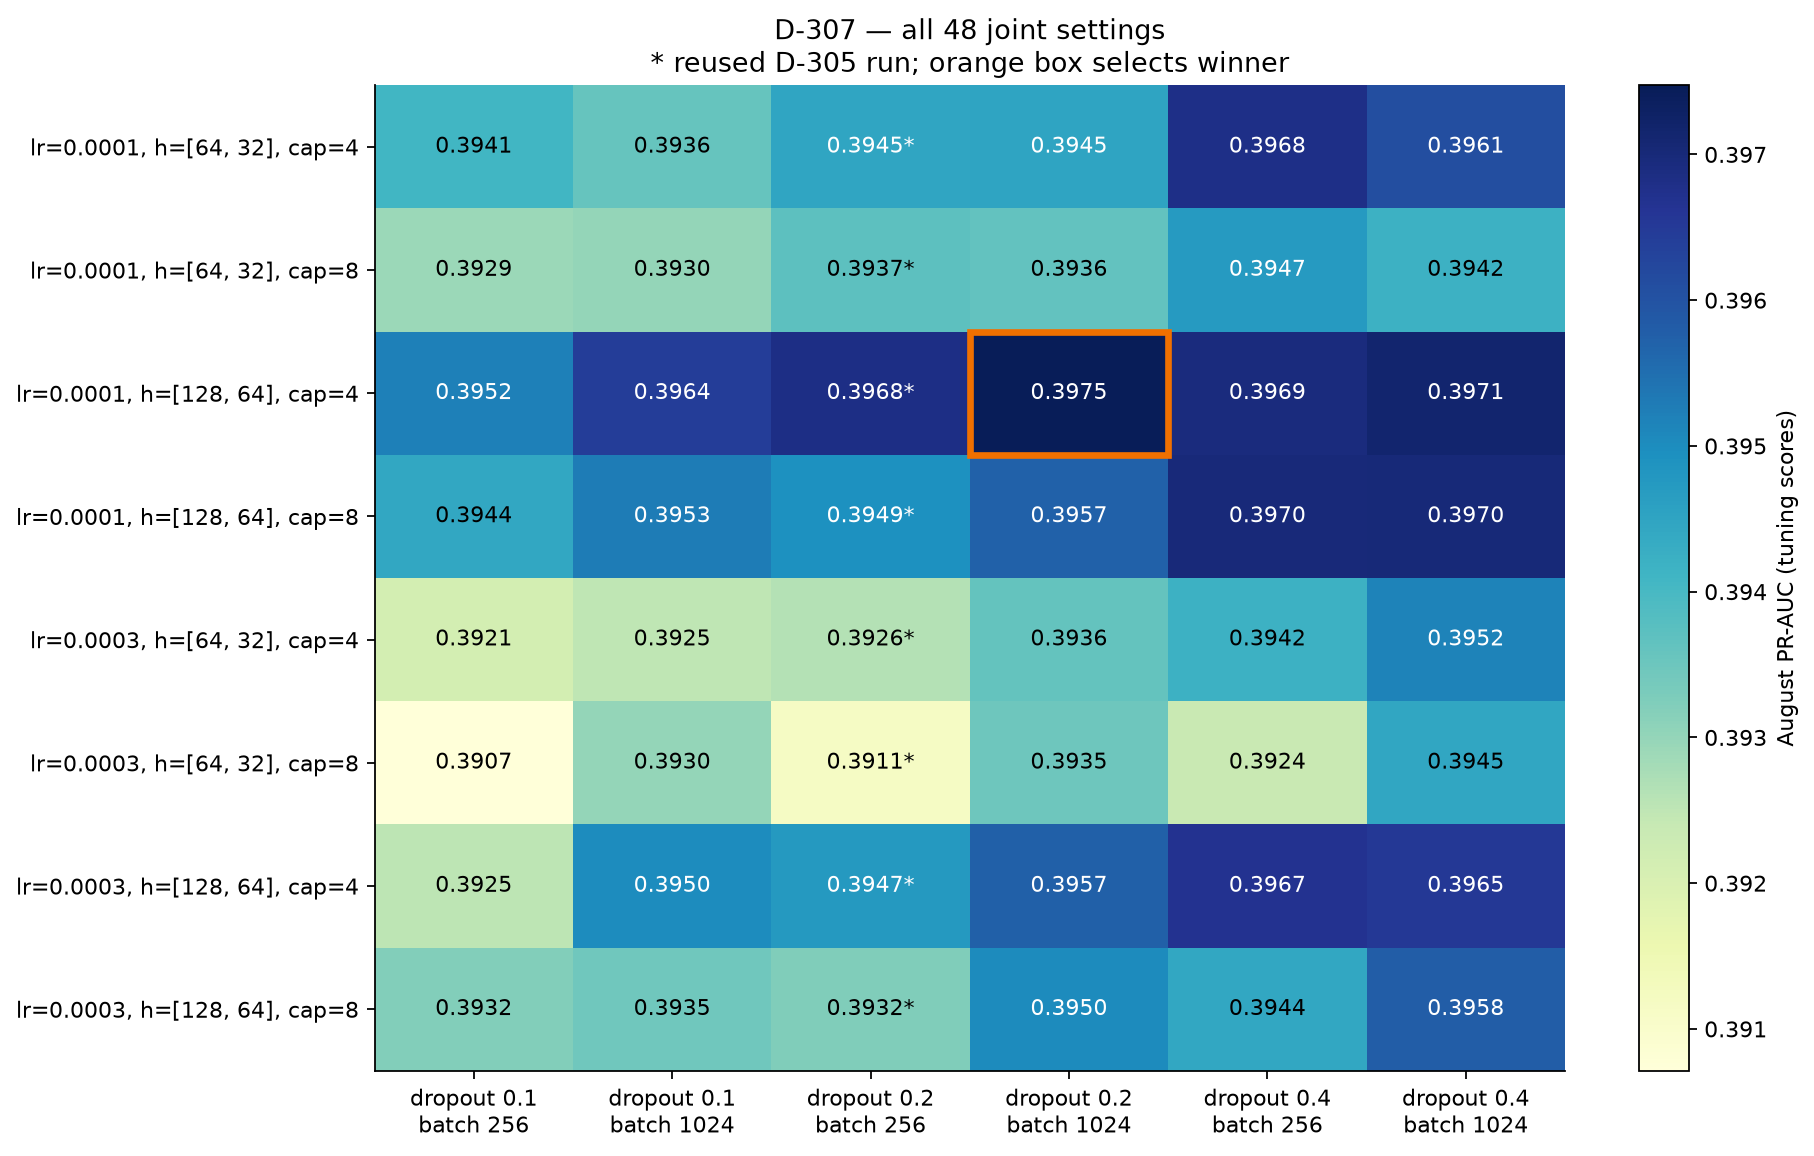

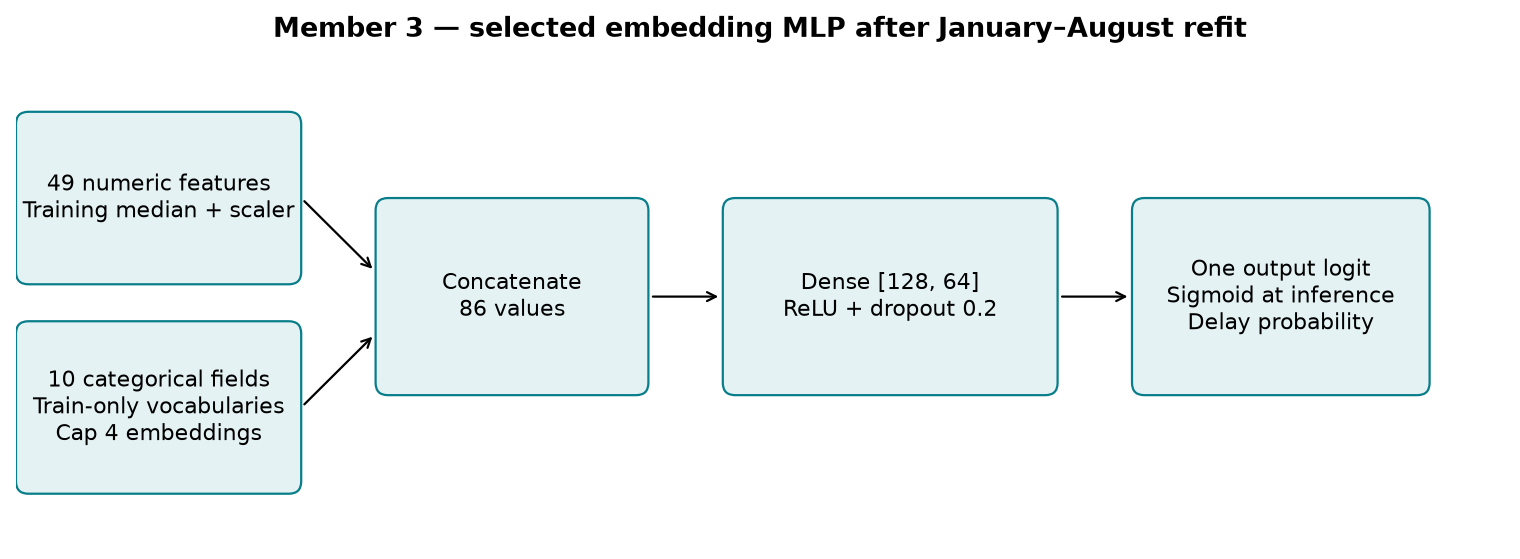

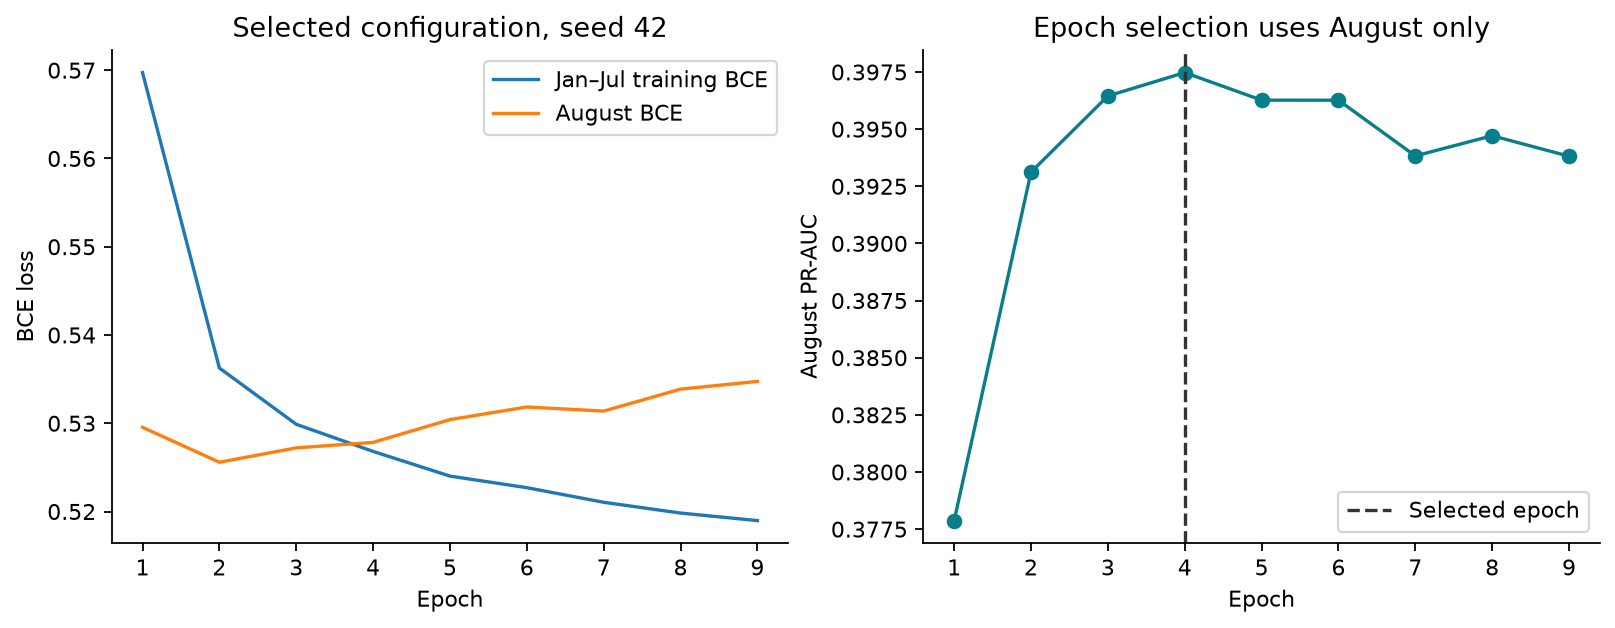

In [2]:
display(pd.read_csv(RESULT / 'grid_august.csv'))
display(pd.read_csv(RESULT / 'august_seed_selection.csv'))
FIGURE = ROOT / 'reports/figures/phase2_member3/d307'
display(Image(filename=str(FIGURE / 'august_grid.png')))
display(Image(filename=str(FIGURE / 'embedding_architecture.png')))
display(Image(filename=str(FIGURE / 'training_curves.png')))

## Frozen September–October comparison

The same 55,628 flights are used for all models. Neural scores are reported across five seeds.

,model,period,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,brier_score_mean,brier_score_std,ece_10_mean,ece_10_std,mean_probability_mean,mean_probability_std
1,embedding,sep_oct,0.275719,0.003469,0.674828,0.001682,0.128265,0.000465,0.050340,0.004119,0.207293,0.004119
4,gru,sep_oct,0.294573,0.005517,0.674338,0.003839,0.136002,0.004672,0.086280,0.014291,0.243231,0.014288
7,lr,sep_oct,0.289590,NaN,0.679999,NaN,0.185537,NaN,0.233413,NaN,0.390366,NaN
10,mlp,sep_oct,0.283929,0.004295,0.671868,0.002738,0.133268,0.002572,0.075744,0.014849,0.232668,0.014859


,model,period,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,brier_score_mean,brier_score_std,ece_10_mean,ece_10_std,mean_probability_mean,mean_probability_std,result
1,embedding,sep_oct,0.276201,0.002424,0.675276,0.001707,0.127935,0.000568,0.047321,0.004378,0.204274,0.004378,D-306 historical
1,embedding,sep_oct,0.275719,0.003469,0.674828,0.001682,0.128265,0.000465,0.050340,0.004119,0.207293,0.004119,D-307 final


,comparison,difference,ci_low,ci_high,excludes_zero
0,embedding - mlp,-0.008210,-0.026680,0.011583,False
1,embedding - lr,-0.013870,-0.021814,-0.003399,True
2,embedding - gru,-0.018854,-0.039689,0.002264,False


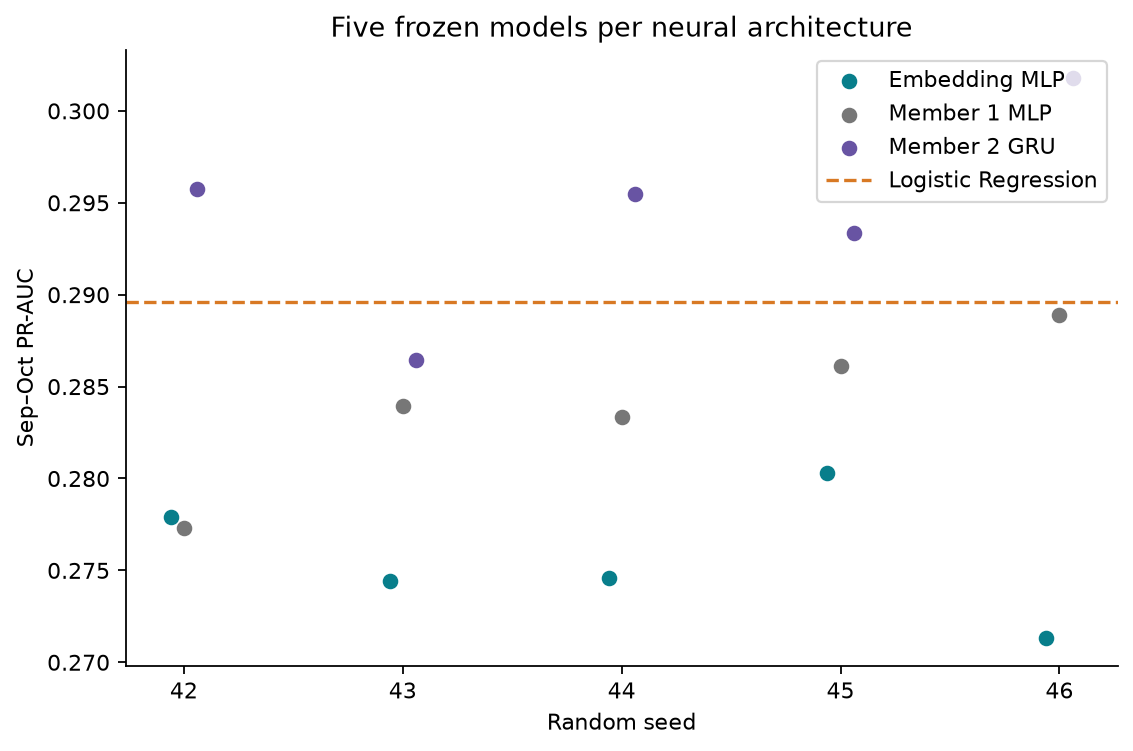

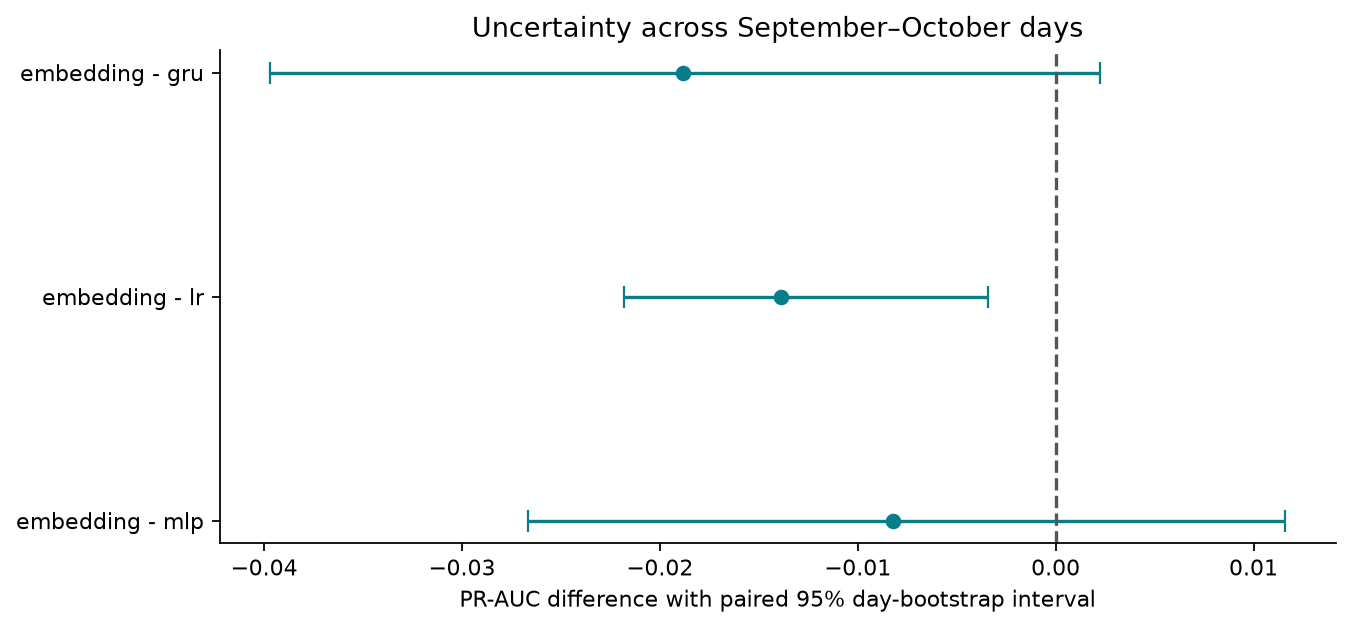

In [3]:
comparison = pd.read_csv(RESULT / 'comparison.csv')
display(comparison.query("period == 'sep_oct'"))
previous = pd.read_csv(RESULT.parent / 'comparison.csv')
versions = pd.concat([previous.assign(result='D-306 historical'), comparison.assign(result='D-307 final')])
display(versions.query("model == 'embedding' and period == 'sep_oct'"))
display(pd.read_csv(RESULT / 'bootstrap_pr_auc_differences.csv'))
display(Image(filename=str(FIGURE / 'seed_comparison.png')))
display(Image(filename=str(FIGURE / 'bootstrap_differences.png')))

## Limitations

Raw probabilities require calibration. Evaluation periods were viewed in earlier project iterations. Confidence intervals describe day-level variation for these fixed designs. Full protocol, interpretation and source references are in `docs/phase2_member3_embedding_mlp.md`.